# Section 3 · Task 3.1 — Construct Dynamic Circuits

**Exam:** C1000-179 *Fundamentals of Quantum Computing Using Qiskit v2.X Developer*
**Section 3:** Create quantum circuits (≈ 18 % of the exam) → **Task 3.1: Construct dynamic circuits**
**Official reference from the study guide:** [Classical feedforward and control flow (dynamic circuits)](https://quantum.cloud.ibm.com/docs/en/guides/classical-feedforward-and-control-flow)
Related (hardware limits): [Execute dynamic circuits](https://quantum.cloud.ibm.com/docs/en/guides/execute-dynamic-circuits) · API: [`qiskit.circuit.classical`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/circuit_classical)

*(Task 2.2 showed how dynamic circuits are **drawn and measured**. Here you learn to **construct** them properly.)*

---

### IBM's self-test applied here
1. **How** do you build a circuit that measures mid-circuit and acts on the result — with `if_test`, `switch`, `for_loop`, `while_loop`, classical expressions and `store`?
2. **Why** do dynamic circuits exist — what can they do that a static circuit cannot (state preparation with constant depth, long-range entanglement, teleportation, repeat-until-success)?
3. **What goes wrong if you do it incorrectly?** (condition bit order, forgetting the `with`, running on a simulator that cannot execute control flow, transpiling to a backend that does not support it, hardware that supports only `if_test` …)

### What you will be able to do afterwards
- Build all four control-flow constructs, with **else** branches, **register conditions**, **multi-value cases** and **default** cases
- Use the **loop parameter**, `break_loop` and `continue_loop`
- Write conditions with **classical expressions** (`expr`) and keep intermediate results with **`store`**
- Inspect a dynamic circuit's structure (`IfElseOp`, blocks, conditions)
- Build **teleportation** and the guide's **constant-depth GHZ** circuit, and *verify* them
- Know which tools can **run** control flow (Aer ✔, `StatevectorSampler` ✘, hardware: `if_test` only, per IBM's docs) and how to **transpile** it

Exercise cells are stubs returning `None`, so the notebook runs end-to-end without your answers. **Solutions are at the end.**

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from IPython.display import display
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit import IfElseOp, ForLoopOp, WhileLoopOp, SwitchCaseOp, Parameter
from qiskit.circuit.classical import expr, types
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_histogram
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.transpiler.exceptions import TranspilerError
from qiskit_aer.primitives import SamplerV2 as AerSampler

print("qiskit", qiskit.__version__)

def _todo(name):
    print(f"⏳ {name}: not attempted yet — fill in the TODO above and re-run this cell.")

def run(qc, shots=3000, seed=7):
    # Run a dynamic circuit on Aer's SamplerV2 and return the PubResult (use result.data.<register>)
    return AerSampler(seed=seed).run([qc], shots=shots).result()[0]

qiskit 2.6.1


---
## 1 · What is a dynamic circuit?

A **static** circuit is: gates → measure everything at the **end**. A **dynamic** circuit may

1. **measure mid-circuit** and keep computing on the same qubits,
2. **reset** qubits (so they can be re-used),
3. **branch / loop on classical data** produced by those measurements — **classical feedforward**,
4. do small amounts of **classical computation** (parity, comparisons, …) during execution.

The study guide lists use cases: **efficient state preparation** (GHZ, W, matrix-product states), **long-range entanglement** with shallow circuits, and efficient **sampling of IQP-like circuits**. Teleportation and error-correction syndrome decoding are the textbook examples.

### 1.1 The four control-flow constructs

Each is a method on `QuantumCircuit` that returns a **context manager**, so you normally write them with a `with` block: the gates you add inside the block become the *body*.

| Construct | Method | Runs the body… |
|---|---|---|
| If / else | `qc.if_test(condition)` (+ `as else_:` … `with else_:`) | once, if the condition holds; else-block otherwise |
| Switch | `qc.switch(target)` and `with case(values…)` | the one matching case (or `case.DEFAULT`) — **no fall-through** |
| For loop | `qc.for_loop(indexset)` | once per element of the index set |
| While loop | `qc.while_loop(condition)` | repeatedly while the condition holds |

(`break_loop()` and `continue_loop()` work inside loops.)

### 1.2 The old way is gone
Before Qiskit 2.0 you wrote `gate.c_if(creg, value)`. **`c_if` was removed.** Everything below replaces it.

In [2]:
qc = QuantumCircuit(1, 1)
try:
    qc.x(0).c_if(qc.clbits[0], 1)
except AttributeError as e:
    print("c_if is gone ->", type(e).__name__, ":", e)

c_if is gone -> AttributeError : 'InstructionSet' object has no attribute 'c_if'


### 1.3 Building blocks you need first: mid-circuit `measure` and `reset`

- `qc.measure(q, c)` in the *middle* of a circuit is allowed; the qubit collapses to $|0\rangle$ or $|1\rangle$ and **continues** to exist.
- `qc.reset(q)` forces a qubit to $|0\rangle$ (non-unitary). **Measure-then-reset** lets you re-use a qubit — and a classical bit keeps the information.

In [3]:
reuse = QuantumCircuit(1, 2)
reuse.h(0);  reuse.measure(0, 0)        # first random bit
reuse.reset(0)
reuse.h(0);  reuse.measure(0, 1)        # second, independent random bit — on the SAME qubit
print(reuse)
counts = run(reuse).data.c.get_counts()
print("two independent random bits from ONE qubit:", counts)

     ┌───┐┌─┐     ┌───┐┌─┐
  q: ┤ H ├┤M├─|0>─┤ H ├┤M├
     └───┘└╥┘     └───┘└╥┘
c: 2/══════╩════════════╩═
           0            1 
two independent random bits from ONE qubit: {'01': 720, '10': 750, '11': 770, '00': 760}


---
## 2 · `if_test`

```python
with qc.if_test((clbit_or_register, value)):      # tuple condition
    ...body...
```

The **condition** is either a tuple `(Clbit | ClassicalRegister, int)` or a **classical expression** (§6). The body runs when the bit/register **equals** the integer.

### 2.1 Conditioning on one classical bit (the guide's first example)
Apply `H`, measure; if the result is 1, apply `X` to flip the qubit back to 0; measure again. The second outcome must be 0 with certainty.

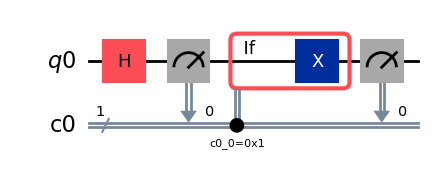

counts: {'0': 3000}


In [4]:
qubits = QuantumRegister(1)
clbits = ClassicalRegister(1)
circuit = QuantumCircuit(qubits, clbits)
(q0,) = qubits
(c0,) = clbits

circuit.h(q0)
circuit.measure(q0, c0)
with circuit.if_test((c0, 1)):
    circuit.x(q0)
circuit.measure(q0, c0)

display(circuit.draw("mpl"))
print("counts:", run(circuit).data[clbits.name].get_counts())

> **Note on the register name.** Registers created as `ClassicalRegister(1)` get an auto-generated name (`c0`, `c1`, …). The result lives under that name, so we read it with `data[clbits.name]`. If you name it yourself (`ClassicalRegister(1, "c")`) you can write `data.c`.

### 2.2 `else`
Capture the context manager with `as else_`, then open a second block with `with else_:`. The else block runs **exactly when the if block did not**.

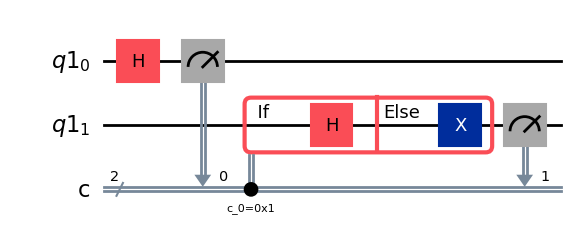

counts (key = c1 c0): {'11': 759, '10': 1510, '01': 731}
c0=0 -> X on q1 -> c1=1 always -> '10' ≈ 50 %;   c0=1 -> H on q1 -> '01','11' ≈ 25 % each


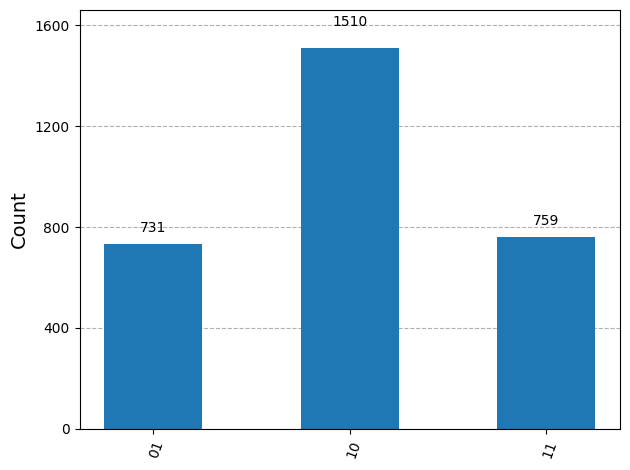

In [5]:
qubits = QuantumRegister(2); clbits = ClassicalRegister(2, "c")
circuit = QuantumCircuit(qubits, clbits)
(q0, q1) = qubits; (c0, c1) = clbits

circuit.h(q0)
circuit.measure(q0, c0)
with circuit.if_test((c0, 1)) as else_:
    circuit.h(q1)             # if c0 == 1
with else_:
    circuit.x(q1)             # else  (c0 == 0)
circuit.measure(q1, c1)

display(circuit.draw("mpl"))
counts = run(circuit).data.c.get_counts()
print("counts (key = c1 c0):", counts)
print("c0=0 -> X on q1 -> c1=1 always -> '10' ≈ 50 %;   c0=1 -> H on q1 -> '01','11' ≈ 25 % each")
plot_histogram(counts)

### 2.3 Conditioning on a whole register
`(clbits, value)` compares the **register as an integer**: classical bit 0 is the **least significant** bit (the same little-endian rule as everywhere in Qiskit). The drawing shows the condition as one circle per bit: **solid = 1, outlined = 0**.

In the guide's example the register has three bits but only two are measured; the third is deliberately specified as 0 in the condition `0b001` (c2=0, c1=0, c0=1) — "the first qubit measured 1 and the second 0".

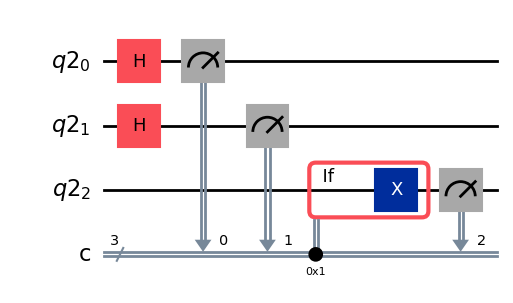

counts: {'011': 759, '010': 770, '101': 731, '000': 740}
c = 001 would trigger X on q2, turning it into 101 — so '001' never survives: True


In [6]:
qubits = QuantumRegister(3); clbits = ClassicalRegister(3, "c")
circuit = QuantumCircuit(qubits, clbits)
(q0, q1, q2) = qubits; (c0, c1, c2) = clbits

circuit.h([q0, q1])
circuit.measure(q0, c0)
circuit.measure(q1, c1)
with circuit.if_test((clbits, 0b001)):
    circuit.x(q2)
circuit.measure(q2, c2)

display(circuit.draw("mpl"))
counts = run(circuit).data.c.get_counts()
print("counts:", counts)
print("c = 001 would trigger X on q2, turning it into 101 — so '001' never survives:", "001" not in counts)

### 2.4 Nesting and the structure behind the scenes
`if_test` blocks can be nested (an *and*). Under the hood each block becomes an **`IfElseOp`** instruction holding **sub-circuits** (the *blocks*). Knowing this lets you inspect, count and test dynamic circuits programmatically.

In [7]:
nested = QuantumCircuit(3, 3)
nested.h([0, 1]); nested.measure([0, 1], [0, 1])
with nested.if_test((nested.clbits[0], 1)):
    with nested.if_test((nested.clbits[1], 1)):          # inner block runs only if BOTH bits are 1
        nested.x(2)
nested.measure(2, 2)
print("top-level ops :", dict(nested.count_ops()))
print("counts        :", run(nested).data.c.get_counts(), " (c2 = 1 only when c1 = c0 = 1)")

# --- structure of an IfElseOp ---
qc = QuantumCircuit(2, 2); qc.h(0); qc.measure(0, 0)
with qc.if_test((qc.clbits[0], 1)) as else_:
    qc.x(1); qc.x(1); qc.z(1)
with else_:
    qc.y(1)
op = next(i.operation for i in qc.data if i.operation.name == "if_else")
print("\ntype      :", type(op).__name__)
print("condition :", op.condition)
print("blocks    :", [dict(b.count_ops()) for b in op.blocks], " <- [true body, false body]")

top-level ops : {'measure': 3, 'h': 2, 'if_else': 1}


counts        : {'111': 759, '010': 770, '001': 731, '000': 740}  (c2 = 1 only when c1 = c0 = 1)

type      : IfElseOp
condition : (<Clbit register=(2, "c"), index=0>, 1)
blocks    : [{'x': 2, 'z': 1}, {'y': 1}]  <- [true body, false body]


### 2.5 Without the `with`-builder: explicit operations
Everything the builder does can be written with the operation classes. This is useful when you generate circuits programmatically, and it shows exactly what the builder produces.

| Builder | Explicit |
|---|---|
| `with qc.if_test(cond): …` | `qc.if_else(cond, true_body, false_body, qubits, clbits)` or `qc.append(IfElseOp(cond, true_body, false_body), qubits, clbits)` |
| `with qc.for_loop(idx) as i: …` | `qc.for_loop(idx, loop_parameter, body, qubits, clbits)` |
| `with qc.while_loop(cond): …` | `qc.while_loop(cond, body, qubits, clbits)` |
| `with qc.switch(t) as case: …` | `qc.switch(t, cases, qubits, clbits)` |

The body is an ordinary `QuantumCircuit` whose **qubits/clbits are mapped** to those you pass.

In [8]:
body = QuantumCircuit(1); body.x(0)                          # body acts on ONE qubit

explicit = QuantumCircuit(2, 1)
explicit.h(0); explicit.measure(0, 0)
explicit.if_else((explicit.clbits[0], 1), body, None, [1], [])     # run `body` on qubit 1 if c0 == 1
explicit.measure_all(add_bits=False) if False else None
print(explicit.draw("text"))

# Same circuit with the builder:
builder = QuantumCircuit(2, 1)
builder.h(0); builder.measure(0, 0)
with builder.if_test((builder.clbits[0], 1)):
    builder.x(1)
print("both contain one IfElseOp:", explicit.count_ops().get("if_else"), builder.count_ops().get("if_else"))

     ┌───┐┌─┐                          
q_0: ┤ H ├┤M├──────────────────────────
     └───┘└╥┘  ┌──────  ┌───┐ ───────┐ 
q_1: ──────╫───┤ If-0  ─┤ X ├  End-0 ├─
           ║   └──╥───  └───┘ ───────┘ 
           ║ ┌────╨────┐               
c: 1/══════╩═╡ c_0=0x1 ╞═══════════════
           0 └─────────┘               
both contain one IfElseOp: 1 1


---
## 3 · `switch`

`if_test` handles one condition (+ else). `switch` selects among **many values** of a bit, a register or an integer expression.

```python
with qc.switch(target) as case:
    with case(v1, v2):        # one block may handle several values
        ...
    with case(v3):
        ...
    with case(case.DEFAULT):  # everything that was not listed
        ...
```

**Rules**
- **Only one block ever runs — there is no fall-through** (unlike C).
- A value may appear in **only one** case.
- `case.DEFAULT` must be **last** and is optional (if absent and nothing matches, nothing happens).
- The target must be a **bit, a register, or an unsigned-integer expression**.

### 3.1 One bit (guide): equivalent to if/else

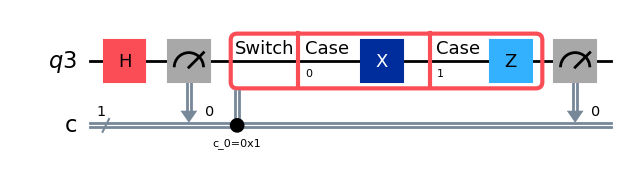

counts: {'1': 3000}   <- always 1


In [9]:
qubits = QuantumRegister(1); clbits = ClassicalRegister(1, "c")
circuit = QuantumCircuit(qubits, clbits)
(q0,) = qubits; (c0,) = clbits

circuit.h(q0)
circuit.measure(q0, c0)
with circuit.switch(c0) as case:
    with case(0):
        circuit.x(q0)          # |0> -> |1>
    with case(1):
        circuit.z(q0)          # |1> -> -|1>   (phase only; still reads 1)
circuit.measure(q0, c0)
display(circuit.draw("mpl"))
print("counts:", run(circuit).data.c.get_counts(), "  <- always 1")

### 3.2 Several values per case and a default (guide)
Measure two qubits; if the result is `00` or `11` apply `Z` to a third qubit, if `01` apply `Y`, otherwise apply `X`; measure the third qubit.

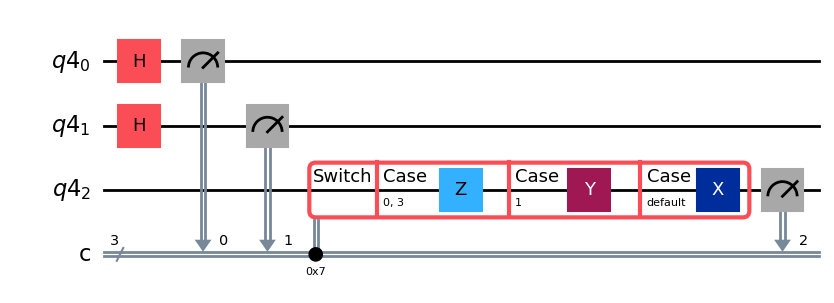

counts: {'011': 759, '110': 770, '101': 731, '000': 740}
 key c2c1c0:  000 -> Z (q2 stays 0)  -> '000'
              011 -> Z               -> '011'   (c2 is still 0 when the switch is evaluated)
              001 -> Y (q2 -> 1)     -> '101'
              010 -> default X       -> '110'


In [10]:
qubits = QuantumRegister(3); clbits = ClassicalRegister(3, "c")
circuit = QuantumCircuit(qubits, clbits)
(q0, q1, q2) = qubits; (c0, c1, c2) = clbits

circuit.h([q0, q1])
circuit.measure(q0, c0)
circuit.measure(q1, c1)
with circuit.switch(clbits) as case:
    with case(0b000, 0b011):
        circuit.z(q2)
    with case(0b001):
        circuit.y(q2)
    with case(case.DEFAULT):
        circuit.x(q2)
circuit.measure(q2, c2)
display(circuit.draw("mpl"))
counts = run(circuit).data.c.get_counts()
print("counts:", counts)
for line in [" key c2c1c0:  000 -> Z (q2 stays 0)  -> '000'",
             "              011 -> Z               -> '011'   (c2 is still 0 when the switch is evaluated)",
             "              001 -> Y (q2 -> 1)     -> '101'",
             "              010 -> default X       -> '110'"]:
    print(line)

> Compare with the guide's sample output `{'101', '110', '011', '000'}` — the same four keys.

### 3.3 Inspecting a `SwitchCaseOp`

In [11]:
op = next(i.operation for i in circuit.data if i.operation.name == "switch_case")
print(type(op).__name__, "| target:", op.target)
for labels, block in op.cases_specifier():
    print("  case", labels, "->", dict(block.count_ops()))

SwitchCaseOp | target: ClassicalRegister(3, 'c')
  case (0, 3) -> {'z': 1}
  case (1,) -> {'y': 1}
  case (<default case>,) -> {'x': 1}


---
## 4 · `for_loop`

```python
with qc.for_loop(range(5)) as i:      # `i` is a Parameter you can use in gate angles
    ...
```

- The **index set** is any iterable of integers: `range(n)`, a list, a tuple.
- The loop variable (the `as i` part) is a symbolic `Parameter`. Use it in rotation angles; if you do not need it, write `as _` or omit `as`.
- The loop body is stored **once** and repeated at runtime — the circuit does **not** grow with the loop count (unlike a Python `for` that unrolls gates).

### 4.1 The guide's example: five X gates

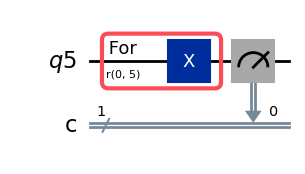

5 X gates (odd) -> |1>: {'1': 3000}
size with for_loop: 2 | size when unrolled in Python: 6


In [12]:
qubits = QuantumRegister(1); clbits = ClassicalRegister(1, "c")
circuit = QuantumCircuit(qubits, clbits)
(q0,) = qubits; (c0,) = clbits

with circuit.for_loop(range(5)) as _:
    circuit.x(q0)
circuit.measure(q0, c0)
display(circuit.draw("mpl"))
print("5 X gates (odd) -> |1>:", run(circuit).data.c.get_counts())

# Compare circuit size: loop vs Python-unrolled
unrolled = QuantumCircuit(1, 1)
for _ in range(5): unrolled.x(0)
unrolled.measure(0, 0)
print("size with for_loop:", circuit.size(), "| size when unrolled in Python:", unrolled.size())

### 4.2 Using the loop variable
Rotate by $i\cdot\pi/6$ for $i=0,1,2,3$: the angles add to $(0+1+2+3)\pi/6=\pi$, so $R_Y$ totals $\pi$ and $|0\rangle\to|1\rangle$.

indexset: range(0, 4) | loop parameter: _loop_i_1 Parameter
counts  : {'1': 3000}  <- total rotation π


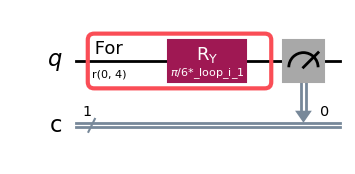

In [13]:
qc = QuantumCircuit(1, 1)
with qc.for_loop(range(4)) as i:
    qc.ry(i * np.pi / 6, 0)               # i is a Parameter; i*pi/6 is a ParameterExpression
qc.measure(0, 0)
op = qc.data[0].operation
print("indexset:", op.params[0], "| loop parameter:", op.params[1], type(op.params[1]).__name__)
print("counts  :", run(qc).data.c.get_counts(), " <- total rotation π")
qc.draw("mpl")

### 4.3 `break_loop` and `continue_loop`
Both are only valid **inside a loop body**, normally guarded by an `if_test`:

- `break_loop()` — leave the loop immediately.
- `continue_loop()` — skip the rest of this iteration, go to the next.

Example: try up to **3 times** to measure a `1`; stop as soon as one appears. The final bit is `1` unless all three tries gave 0 → $P(1)=1-(1/2)^3=0.875$.

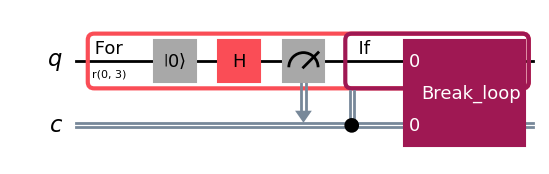

counts: {'1': 6961, '0': 1039} | P(1) = 0.87 (theory 0.875)


In [14]:
qc = QuantumCircuit(1, 1)
with qc.for_loop(range(3)):
    qc.reset(0)
    qc.h(0)
    qc.measure(0, 0)
    with qc.if_test((qc.clbits[0], 1)):
        qc.break_loop()
display(qc.draw("mpl", cregbundle=False))
counts = run(qc, shots=8000).data.c.get_counts()
print("counts:", counts, "| P(1) =", round(counts.get("1", 0) / 8000, 3), "(theory 0.875)")

---
## 5 · `while_loop`

```python
with qc.while_loop(condition):     # same condition forms as if_test
    ...body...                      # must (eventually) change the condition!
```

The condition is **checked before each iteration**. The body must *update the classical data being tested* (normally with a fresh measurement), otherwise the loop never ends.

### 5.1 The guide's example: repeat until the outcome is not `11`

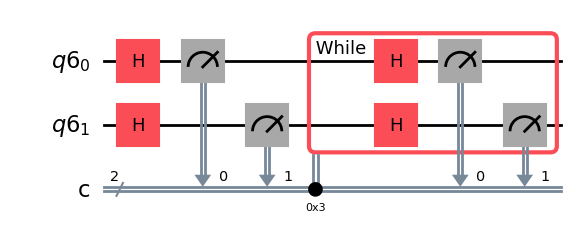

counts: {'10': 1010, '01': 1001, '00': 989}   <- '11' never survives; the other three ≈ 1/3 each


In [15]:
qubits = QuantumRegister(2); clbits = ClassicalRegister(2, "c")
circuit = QuantumCircuit(qubits, clbits)
q0, q1 = qubits; c0, c1 = clbits

circuit.h([q0, q1])
circuit.measure(q0, c0)
circuit.measure(q1, c1)
with circuit.while_loop((clbits, 0b11)):
    circuit.h([q0, q1])
    circuit.measure(q0, c0)
    circuit.measure(q1, c1)
display(circuit.draw("mpl"))
counts = run(circuit).data.c.get_counts()
print("counts:", counts, "  <- '11' never survives; the other three ≈ 1/3 each")

This is the **repeat-until-success** pattern: a probabilistic step is retried until a classical "success" flag is seen.

> ⚠️ **Never write a `while` whose condition cannot change** — on a simulator it hangs, on hardware the job is wasted (and hardware does not even support `while`; see §8).

### 5.2 `while` with an expression condition
Conditions may be **expressions** too. Here: loop **while the two measured bits are equal**, so the final result is `01` or `10` (that is, "bits differ").

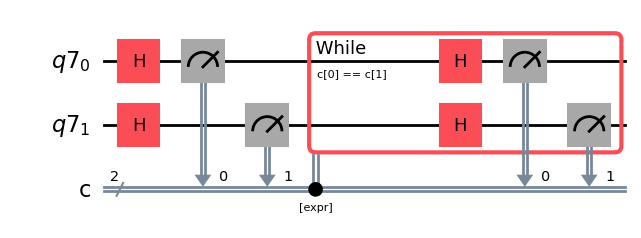

counts: {'10': 1498, '01': 1502}


In [16]:
q = QuantumRegister(2); c = ClassicalRegister(2, "c")
qc = QuantumCircuit(q, c)
qc.h(q); qc.measure(q, c)
with qc.while_loop(expr.equal(c[0], c[1])):         # a boolean expression on two bits
    qc.h(q); qc.measure(q, c)
display(qc.draw("mpl"))
print("counts:", run(qc).data.c.get_counts())

---
## 6 · Classical expressions: `qiskit.circuit.classical.expr`

Tuple conditions can only test "equals a constant". **Expressions** let you test relationships between classical values (`bits`, `registers`) at run time.

```python
from qiskit.circuit.classical import expr, types
```

Expressions are **typed**: `types.Bool()` (a truth value), `types.Uint(n)` (an *n*-bit unsigned integer), plus `Float`/`Duration` in newer versions. `expr.lift(x)` turns a Python/Qiskit object into an expression node (`Value` or `Var`) so you can start an expression chain.

| Family | Constructors | Operands → result |
|---|---|---|
| **Bitwise** | `bit_and`, `bit_or`, `bit_xor`, `bit_not` | bits or unsigned ints → same kind (bit-for-bit) |
| **Logical** | `logic_and`, `logic_or`, `logic_not` | booleans → boolean |
| **Comparison** | `equal`, `not_equal`, `less`, `less_equal`, `greater`, `greater_equal` | values → boolean |
| **Other** | `index(target, i)`, `shift_left`, `shift_right`, `negate`, `cast`, arithmetic `add`, `sub`, `mul`, `div` | |

> There is **no** `logic_xor`; for single bits use `bit_xor` (or `not_equal`).

An expression in `if_test(...)` / `while_loop(...)` must have **Boolean** type; a `switch` target must be an unsigned integer (or a bit/register).

In [17]:
c = ClassicalRegister(3, "c")
a, b = c[0], c[1]
examples = {
    "expr.lift(c)                  ": expr.lift(c),
    "expr.bit_xor(c[0], c[1])      ": expr.bit_xor(a, b),
    "expr.logic_and(c[0], c[1])    ": expr.logic_and(a, b),
    "expr.equal(c, 5)              ": expr.equal(c, 5),
    "expr.greater(c, 2)            ": expr.greater(c, 2),
    "expr.bit_not(c)               ": expr.bit_not(c),
    "expr.lift(5)                  ": expr.lift(5),
}
for text, e in examples.items():
    print(f"{text} -> type: {e.type}")

expr.lift(c)                   -> type: Uint(3)
expr.bit_xor(c[0], c[1])       -> type: Bool()
expr.logic_and(c[0], c[1])     -> type: Bool()
expr.equal(c, 5)               -> type: Bool()
expr.greater(c, 2)             -> type: Bool()
expr.bit_not(c)                -> type: Uint(3)
expr.lift(5)                   -> type: Uint(3)


Note the types: bit-level operations give `Bool`; operations on a whole register stay `Uint(n)` (`bit_not(c)` is 3 bits wide, `equal`/`greater` return `Bool`).

### 6.1 Using expressions in conditions

(a) q2 flipped exactly when c == 11: True


(b) q3 flipped exactly when at least two of three bits are 1: True


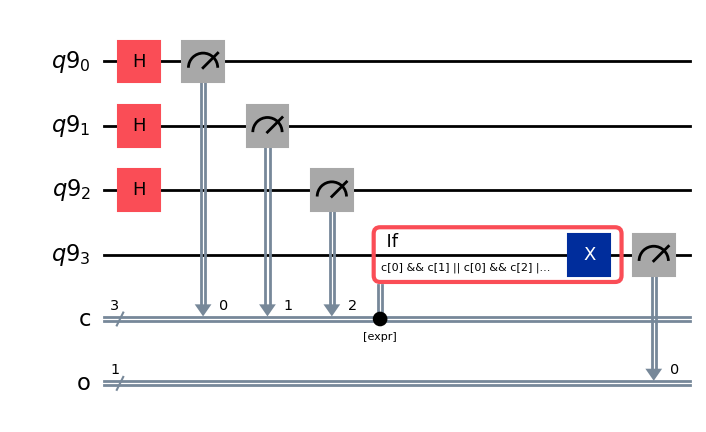

In [18]:
# (a) register comparison: act only when the 2-bit register equals 3
q = QuantumRegister(3); c = ClassicalRegister(2, "c"); o = ClassicalRegister(1, "o")
qc = QuantumCircuit(q, c, o)
qc.h([0, 1]); qc.measure([0, 1], c)
with qc.if_test(expr.equal(c, 3)):
    qc.x(2)
qc.measure(2, o[0])
r = run(qc)
ok = all(int(ob) == (1 if cb == "11" else 0) for cb, ob in zip(r.data.c.get_bitstrings(), r.data.o.get_bitstrings()))
print("(a) q2 flipped exactly when c == 11:", ok)

# (b) majority vote of three measured bits
q = QuantumRegister(4); c = ClassicalRegister(3, "c"); o = ClassicalRegister(1, "o")
qc = QuantumCircuit(q, c, o)
qc.h([0, 1, 2]); qc.measure([0, 1, 2], c)
c0, c1, c2 = c
maj = expr.logic_or(expr.logic_or(expr.logic_and(c0, c1), expr.logic_and(c0, c2)), expr.logic_and(c1, c2))
with qc.if_test(maj):
    qc.x(3)
qc.measure(3, o[0])
r = run(qc)
ok = all(int(ob) == (1 if cb.count("1") >= 2 else 0) for cb, ob in zip(r.data.c.get_bitstrings(), r.data.o.get_bitstrings()))
print("(b) q3 flipped exactly when at least two of three bits are 1:", ok)
qc.draw("mpl")

### 6.2 The guide's flagship example: **constant-depth GHZ state via parity**
Idea: make **Bell pairs** on neighbouring qubits, glue neighbours with CNOTs, **measure** the boundary qubits (and `reset` them), then correct the others with `X` gates whose condition is the **parity** (XOR) of all earlier measurement bits, and finally re-entangle the measured qubits. The whole thing has depth independent of the number of qubits.

We reproduce the guide's circuit and add a final readout of all qubits so we can verify the result *is* a GHZ state (only all-0 and all-1 outcomes).

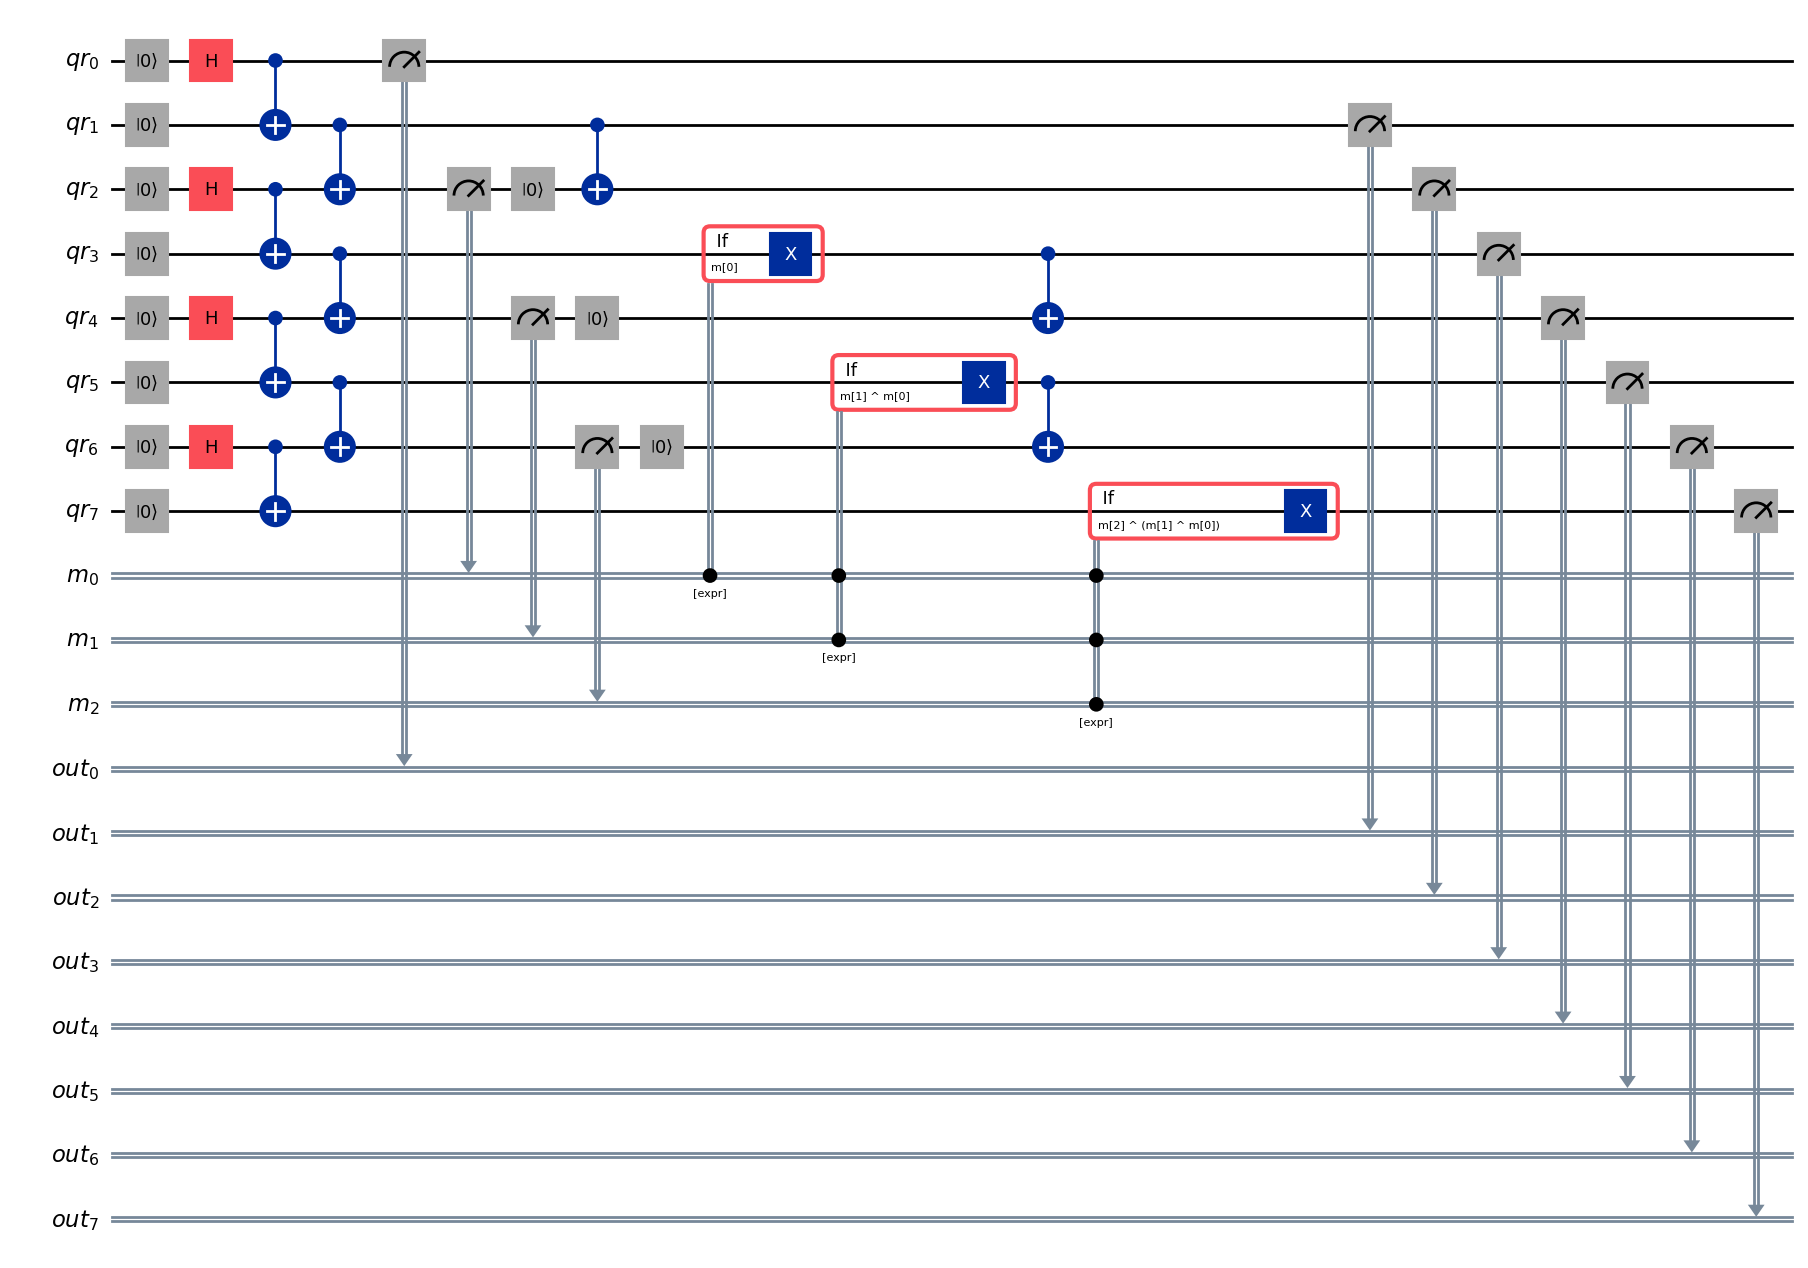

final readout: {'11111111': 1998, '00000000': 2002}
Only |00000000> and |11111111> -> an 8-qubit GHZ state, built with feedforward: True


In [19]:
num_qubits = 8
meas_qubits = list(range(2, num_qubits, 2))          # qubits 2, 4, 6 are measured & reset

qr  = QuantumRegister(num_qubits, "qr")
mr  = ClassicalRegister(len(meas_qubits), "m")
out = ClassicalRegister(num_qubits, "out")           # final readout, added by us for verification
qc = QuantumCircuit(qr, mr, out)

# Local Bell pairs
qc.reset(qr)
qc.h(qr[::2])
for ctrl in range(0, num_qubits, 2):
    qc.cx(qr[ctrl], qr[ctrl + 1])
# Glue neighbouring pairs
for ctrl in range(1, num_qubits - 1, 2):
    qc.cx(qr[ctrl], qr[ctrl + 1])
# Measure the boundary qubits and reset them
for k, q in enumerate(meas_qubits):
    qc.measure(qr[q], mr[k])
    qc.reset(qr[q])
# Parity-conditioned X corrections
for tgt in range(num_qubits):
    if tgt in meas_qubits:
        continue
    left_bits = [k for k, q in enumerate(meas_qubits) if q < tgt]      # measurement bits to the LEFT of tgt
    if not left_bits:
        continue
    parity = expr.lift(mr[left_bits[0]])                               # lift the first bit to an expression
    for k in left_bits[1:]:
        parity = expr.bit_xor(mr[k], parity)                           # XOR in the others
    with qc.if_test(parity):
        qc.x(qr[tgt])
# Re-entangle the measured qubits
for ctrl in range(1, num_qubits - 1, 2):
    qc.cx(qr[ctrl], qr[ctrl + 1])
qc.measure(qr, out)

display(qc.draw(output="mpl", style="iqp", idle_wires=False, fold=-1, cregbundle=False))
counts = run(qc, shots=4000).data.out.get_counts()
print("final readout:", counts)
print("Only |00000000> and |11111111> -> an 8-qubit GHZ state, built with feedforward:", set(counts) == {"00000000", "11111111"})

The conditioning expression is built **in a loop** by repeatedly XOR-ing in the next measurement bit — expressions are ordinary Python objects, so they compose. (`mr[k]` is lifted automatically when it is an *argument* of `bit_xor`; only the very first term needed an explicit `expr.lift` so the chain starts as an expression.)

### 6.3 `store`: save an expression's value
`qc.store(target, value)` evaluates `value` at run time and **writes it into `target`** (a classical bit, a classical register, or a `Var`). Use it when the same expression is needed more than once — it is computed once, and the compiler can parallelise operations.

The guide stores the bitwise NOT of a register and then conditions on the parity of the stored bits, picking bit *i* of the register with **`expr.index(register, i)`**. The installed Aer simulator cannot execute `expr.index`; so below we build the guide's circuit exactly (it is valid Qiskit and meant for hardware), and then **run an equivalent version that addresses the bits directly** (`temp[0]`, …) to check the logic.

In [20]:
# --- The guide's version (builds and draws fine) ---
qregs = QuantumRegister(4, "q")
creg = ClassicalRegister(3, "c")
temp = ClassicalRegister(3, "temp")                    # a plain ClassicalRegister used as the store target
guide = QuantumCircuit(qregs, creg, temp)
guide.h([0, 1, 2])
guide.measure([0, 1, 2], creg)
guide.store(temp, expr.bit_not(creg))                  # temp = ~c   (one parallel step)
parity = expr.bit_xor(expr.bit_xor(expr.index(temp, 0), expr.index(temp, 1)), expr.index(temp, 2))
with guide.if_test(parity):
    guide.x(3)
guide.measure([0, 1, 2], creg)
print("built guide's store-example. ops:", dict(guide.count_ops()))
try:
    run(guide, shots=10)
except Exception as e:
    print("Aer cannot execute expr.index ->", type(e).__name__)

built guide's store-example. ops: {'measure': 6, 'h': 3, 'store': 1, 'if_else': 1}
Aer cannot execute expr.index -> AerError


In [21]:
# --- Equivalent version that Aer CAN run: index the register's bits directly (temp[0], temp[1], temp[2]) ---
qregs = QuantumRegister(4, "q")
creg = ClassicalRegister(3, "c")
temp = ClassicalRegister(3, "temp")
fin = ClassicalRegister(1, "fin")
qc = QuantumCircuit(qregs, creg, temp, fin)
qc.h([0, 1, 2])
qc.measure([0, 1, 2], creg)
qc.store(temp, expr.bit_not(creg))                                  # temp = NOT c
parity = expr.bit_xor(expr.bit_xor(temp[0], temp[1]), temp[2])
with qc.if_test(parity):
    qc.x(3)
qc.measure(3, fin[0])

r = run(qc, shots=2000)
c_b, t_b, f_b = r.data.c.get_bitstrings(), r.data.temp.get_bitstrings(), r.data.fin.get_bitstrings()
ok_not    = all(t == "".join("1" if ch == "0" else "0" for ch in c) for c, t in zip(c_b, t_b))
ok_parity = all(int(f) == (t.count("1") % 2) for t, f in zip(t_b, f_b))
print("temp == NOT c in every shot        :", ok_not)
print("q3 flipped iff parity(temp) is odd  :", ok_parity)
print("example shots (c, temp, fin):", list(zip(c_b, t_b, f_b))[:4])

temp == NOT c in every shot        : True
q3 flipped iff parity(temp) is odd  : True
example shots (c, temp, fin): [('011', '100', '1'), ('110', '001', '1'), ('101', '010', '1'), ('011', '100', '1')]


### 6.4 Typed variables (`Var`) — a first look
Qiskit 2 lets a circuit own **typed classical variables**: `qc.add_var(name, initial_value)` (also `add_input`, `add_capture` for circuits used as sub-blocks). They can be written with `store` and read in expressions. The *exam-relevant* points: variables have a **type** (`types.Bool()`, `types.Uint(n)`), you **must `store`** to change them, and they only exist in the circuit that declared (or captured) them.

*(Execution support for `Var`s and arithmetic varies between simulators and hardware — in the installed Aer, arithmetic expressions such as `expr.add` are not executable, which matches IBM's documented hardware limitation "arithmetic operations are not supported". Treat variables as something you **build and inspect** at this level.)*

In [22]:
vqc = QuantumCircuit(1, 1)
counter = vqc.add_var("counter", expr.lift(0, types.Uint(4)))      # a 4-bit unsigned variable initialised to 0
flag    = vqc.add_var("flag", expr.lift(False))                    # a Bool variable
print("counter:", counter.name, counter.type, "| flag:", flag.name, flag.type)
vqc.h(0); vqc.measure(0, 0)
with vqc.if_test(expr.lift(vqc.clbits[0])):
    vqc.store(flag, True)                                          # store is how you change a variable
print("declared vars:", [v.name for v in vqc.iter_declared_vars()])
print("store instructions in the if-body:", dict(vqc.data[-1].operation.blocks[0].count_ops()))

counter: counter Uint(4) | flag: flag Bool()
declared vars: ['counter', 'flag']
store instructions in the if-body: {'store': 1}


In [23]:
# Arithmetic expressions build fine ...
arith = QuantumCircuit(1)
nreg = ClassicalRegister(4, "n")
arith.add_register(nreg)
arith.store(nreg, expr.add(nreg, 1))                 # n = n + 1
print("built:", dict(arith.count_ops()))
# ... but the installed Aer cannot execute them (IBM hardware also documents 'arithmetic operations are not supported')
try:
    run(arith, shots=5)
except Exception as e:
    print("Aer ->", type(e).__name__, ":", str(e)[:80])

built: {'store': 1}
Aer -> AerError : 'unknown op: Binary.Op.ADD'


---
## 7 · A complete example: quantum teleportation with feedforward

Teleportation sends the unknown state of qubit 0 to qubit 2 using a shared Bell pair (q1, q2) and **two classical bits**:

1. Bell pair on (q1, q2).
2. `CX(q0→q1)`, `H(q0)`, **measure** q0 → `c0`, q1 → `c1`.
3. **Feedforward corrections** on q2: `X` if `c1 = 1`, then `Z` if `c0 = 1`.
4. To *verify* without tomography: undo the preparation on q2 and measure — the result must be `0` **every time**.

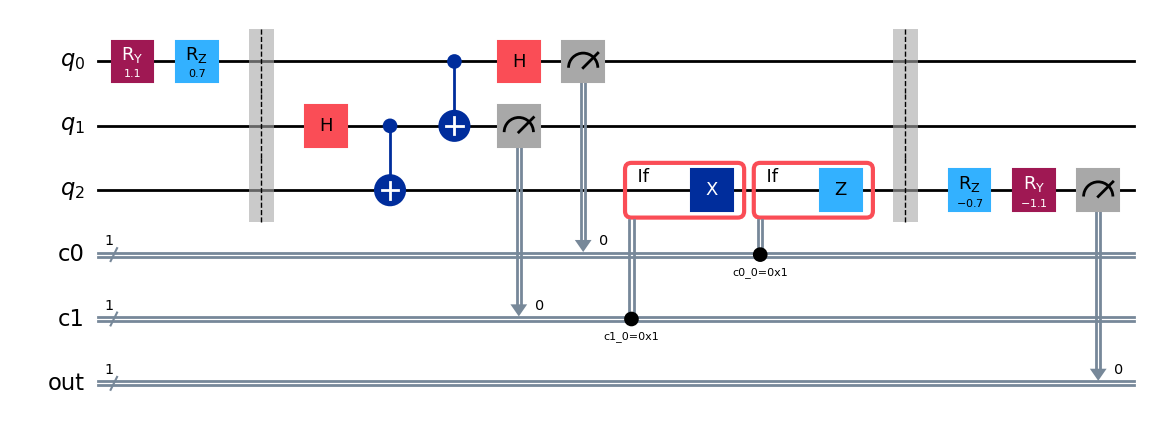

verification bit 'out': {'0': 4000} <- always 0 => the state arrived intact
Alice's two classical bits are uniformly random: {'1': 2005, '0': 1995} {'1': 2025, '0': 1975}


In [24]:
def teleportation(theta, phi):
    q   = QuantumRegister(3, "q")
    c0  = ClassicalRegister(1, "c0")
    c1  = ClassicalRegister(1, "c1")
    out = ClassicalRegister(1, "out")
    qc = QuantumCircuit(q, c0, c1, out)

    qc.ry(theta, 0); qc.rz(phi, 0)            # prepare the unknown state |psi> on q0
    qc.barrier()
    qc.h(1); qc.cx(1, 2)                      # Bell pair
    qc.cx(0, 1); qc.h(0)                      # Bell-basis rotation on (q0, q1)
    qc.measure(0, c0[0]); qc.measure(1, c1[0])
    with qc.if_test((c1[0], 1)):              # feedforward
        qc.x(2)
    with qc.if_test((c0[0], 1)):
        qc.z(2)
    qc.barrier()
    qc.rz(-phi, 2); qc.ry(-theta, 2)          # undo the preparation on the receiver
    qc.measure(2, out[0])
    return qc

tele = teleportation(1.1, 0.7)
display(tele.draw("mpl"))
r = run(tele, shots=4000)
print("verification bit 'out':", r.data.out.get_counts(), "<- always 0 => the state arrived intact")
print("Alice's two classical bits are uniformly random:", r.data.c0.get_counts(), r.data.c1.get_counts())

In [25]:
# What if we 'forget' the feedforward? Remove the corrections and the state does NOT arrive.
def teleportation_no_correction(theta, phi):
    q = QuantumRegister(3, "q"); c0 = ClassicalRegister(1, "c0"); c1 = ClassicalRegister(1, "c1"); out = ClassicalRegister(1, "out")
    qc = QuantumCircuit(q, c0, c1, out)
    qc.ry(theta, 0); qc.rz(phi, 0)
    qc.h(1); qc.cx(1, 2); qc.cx(0, 1); qc.h(0)
    qc.measure(0, c0[0]); qc.measure(1, c1[0])
    qc.rz(-phi, 2); qc.ry(-theta, 2)
    qc.measure(2, out[0]); return qc

print("without corrections:", run(teleportation_no_correction(1.1, 0.7), shots=4000).data.out.get_counts(), " <- wrong about half the time")

without corrections: {'1': 1996, '0': 2004}  <- wrong about half the time


---
## 8 · Where can a dynamic circuit run?

| Tool | Control flow? | Notes |
|---|---|---|
| `Statevector(qc)`, `Operator(qc)` | ❌ | they need a unitary circuit |
| `StatevectorSampler` | ❌ | raises *"cannot handle ControlFlowOp"* |
| **Aer** (`AerSimulator`, `qiskit_aer.primitives.SamplerV2`) | ✅ `if_test`, `switch`, loops, many expressions | some expression kinds (`expr.index`, arithmetic, Bool `Var`s) unsupported in the installed version |
| **IBM hardware** (Qiskit Runtime) | ⚠️ limited | see below |

### 8.1 Hardware (as documented on IBM's *Execute dynamic circuits* page)
The page describes the following. **These details change as IBM updates the service — re-read the live page before the exam.**
- Qiskit Runtime **currently supports only the conditional `if` statement** (`if_test`); **`for`, `while`, `switch` are not supported** on hardware.
- **Arithmetic operations are not supported**; the `Estimator` does not support dynamic circuits (use the `Sampler` and build your own measurement circuits).
- Find capable devices with `service.backends(dynamic_circuits=True)` (or `least_busy(..., dynamic_circuits=True)`).
- A dedicated `MidCircuitMeasure` instruction (qiskit-ibm-runtime ≥ 0.43) is optimised for mid-circuit measurement; it maps to the backend instruction `measure_2`, which not all backends support.
- Control-electronics **memory and latency limits**: a large number of measurements/resets/branches can make a job fail (e.g. measurement buffer overflow).

So: **develop and test on Aer with all constructs; for hardware, restrict yourself to `if_test`.**

### 8.2 Transpilation: the target must advertise control flow
`transpile` refuses control flow when the backend's `Target` does not list those operations. `GenericBackendV2(..., control_flow=True)` simulates a backend that does.

In [26]:
H_shape = [[0, 1], [1, 0], [1, 2], [2, 1], [1, 3], [3, 1], [3, 5], [5, 3], [4, 5], [5, 4], [5, 6], [6, 5]]
no_cf = GenericBackendV2(num_qubits=7, coupling_map=H_shape, seed=1)
with_cf = GenericBackendV2(num_qubits=7, coupling_map=H_shape, seed=1, control_flow=True)
cf_names = ("if_else", "for_loop", "while_loop", "switch_case", "break_loop", "continue_loop")
print("backend without control flow supports:", [o for o in no_cf.operation_names if o in cf_names])
print("backend with    control flow supports:", [o for o in with_cf.operation_names if o in cf_names])

dyn = QuantumCircuit(1, 1); dyn.h(0); dyn.measure(0, 0)
with dyn.if_test((dyn.clbits[0], 1)):
    dyn.x(0)

try:
    transpile(dyn, no_cf)
except TranspilerError as e:
    print("\ntranspile -> no_cf   :", type(e).__name__, "-", e)

t = transpile(dyn, with_cf, seed_transpiler=1)
print("transpile -> with_cf :", dict(t.count_ops()), " (H became rz/sx; the if-block is kept)")

backend without control flow supports: []
backend with    control flow supports: ['if_else', 'while_loop', 'for_loop', 'switch_case']

transpile -> no_cf   : TranspilerError - "The control-flow construct 'if_else' is not supported by the backend."
transpile -> with_cf : {'rz': 2, 'sx': 1, 'measure': 1, 'if_else': 1}  (H became rz/sx; the if-block is kept)


In [27]:
# The body of the if_else was transpiled to native gates (rz, sx, x ...):
inner = next(i.operation for i in t.data if i.operation.name == "if_else").blocks[0]
print("transpiled if-body:", dict(inner.count_ops()), " (the body is transpiled too; X happens to be a native gate here)")

transpiled if-body: {'x': 1}  (the body is transpiled too; X happens to be a native gate here)


---
## 9 · Gotchas checklist

1. **`c_if` no longer exists.** Use `if_test` / `switch` / expressions.
2. **Use `with`.** The constructs return context managers; calling `qc.if_test(...)` without `with` does nothing useful.
3. **Else needs the handle:** `with qc.if_test(c) as else_:` … then `with else_:`.
4. **Register conditions are integers with bit 0 least significant** — `(creg, 0b001)` means bit 0 = 1, others 0. A tuple condition must name the **whole register** (or one bit) and an **int**.
5. **`switch`: no fall-through, values unique, `DEFAULT` last.** Target is a bit, register, or `Uint` expression.
6. **Loop variable is a `Parameter`** (`for_loop(...) as i`); loop bodies are stored **once**, not unrolled.
7. **`break_loop`/`continue_loop` only inside loops**, guarded by a condition.
8. **A `while` whose condition cannot change never ends.**
9. **Expression types matter:** `if_test`/`while_loop` need a **Bool**; bitwise (`bit_*`) vs logical (`logic_*`); there is no `logic_xor`; `expr.lift` starts an expression chain.
10. **`store` writes** into a bit/register/`Var`; a `Var` cannot be modified any other way.
11. **Simulators:** `Statevector`/`Operator`/`StatevectorSampler` cannot run control flow; **Aer can** (with some expression limits).
12. **Hardware:** documented support is `if_test` only, Sampler (not Estimator), plus control-electronics limits — and `transpile` fails if the backend's target lacks the control-flow op.
13. **Measuring the result:** the final data is under the **register's name** (`data.c`, `data.out`, …).

---
## 10 · Exercises

### Exercise 1 — a `switch` that computes XOR
Build a circuit with `q = QuantumRegister(3, "q")`, `c = ClassicalRegister(2, "c")`, `o = ClassicalRegister(1, "o")`:
`H` on q0 and q1, measure them into `c`, then use a **`switch` on `c`** so that qubit q2 is flipped **exactly when the two measured bits differ** (one `case` with two values), and measure q2 into `o`.

In [28]:
def exercise_1():
    # TODO: build the circuit (registers q(3), c(2), o(1)) and return it
    return None

ans1 = exercise_1()

In [29]:
def check_1(qc):
    if qc is None: return _todo("Exercise 1")
    assert "switch_case" in qc.count_ops(), "use qc.switch(...)"
    r = run(qc)
    pairs = list(zip(r.data.c.get_bitstrings(), r.data.o.get_bitstrings()))
    assert all(int(o) == (1 if cb in ("01", "10") else 0) for cb, o in pairs), "q2 must flip exactly when c0 != c1"
    assert {cb for cb, _ in pairs} == {"00", "01", "10", "11"}, "all four measurement outcomes should occur"
    print("✅ Exercise 1 passed — one case with two values handles both 'differ' outcomes.")
check_1(ans1)

⏳ Exercise 1: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 2 — use the loop variable
Build a 1-qubit circuit (`QuantumCircuit(1, 1)`, register `c`) that applies `RY(i·π/6)` inside a **`for_loop` over `range(4)`** (use the loop variable `i`) and then measures. The angles sum to $\pi$, so the result must be `1` with certainty.

In [30]:
def exercise_2():
    # TODO: for_loop with a loop variable used in the angle, then measure
    return None

ans2 = exercise_2()

In [31]:
def check_2(qc):
    if qc is None: return _todo("Exercise 2")
    assert "for_loop" in qc.count_ops(), "use qc.for_loop(...)"
    op = next(i.operation for i in qc.data if i.operation.name == "for_loop")
    assert op.params[1] is not None, "use the loop variable (`as i`) in the body"
    counts = run(qc).data.c.get_counts()
    assert counts == {"1": 3000}, f"expected all 1s, got {counts}"
    print("✅ Exercise 2 passed — the loop body is stored once and run four times with i = 0..3.")
check_2(ans2)

⏳ Exercise 2: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 3 — repeat until the bits differ
`q = QuantumRegister(2)`, `c = ClassicalRegister(2, "c")`. Put both qubits in `|+>`, measure, and **repeat the preparation + measurement while the two bits are equal**, using a `while_loop` with a **classical expression** as the condition. The final counts must only contain `01` and `10`.

In [32]:
def exercise_3():
    # TODO: while_loop with an expression condition
    return None

ans3 = exercise_3()

In [33]:
def check_3(qc):
    if qc is None: return _todo("Exercise 3")
    assert "while_loop" in qc.count_ops(), "use qc.while_loop(...)"
    counts = run(qc).data.c.get_counts()
    assert set(counts) == {"01", "10"}, f"only '01' and '10' may remain, got {counts}"
    assert min(counts.values()) > 1200, f"both outcomes should be ≈ 50 %, got {counts}"
    print("✅ Exercise 3 passed —", counts)
check_3(ans3)

⏳ Exercise 3: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 4 — majority vote with an expression
Registers `q = QuantumRegister(4, "q")`, `c = ClassicalRegister(3, "c")`, `o = ClassicalRegister(1, "o")`. `H` on q0–q2 and measure them into `c`; then, using **one `if_test` whose condition is an expression** (`logic_and`/`logic_or` on the bits), flip q3 **iff at least two of the three bits are 1**; measure q3 into `o`.

In [34]:
def exercise_4():
    # TODO: majority-vote circuit
    return None

ans4 = exercise_4()

In [35]:
def check_4(qc):
    if qc is None: return _todo("Exercise 4")
    assert qc.count_ops().get("if_else") == 1, "use exactly one if_test with an expression condition"
    r = run(qc)
    pairs = list(zip(r.data.c.get_bitstrings(), r.data.o.get_bitstrings()))
    assert all(int(o) == (1 if cb.count("1") >= 2 else 0) for cb, o in pairs), "q3 must flip iff ≥ 2 bits are 1"
    print("✅ Exercise 4 passed — expression conditions let one if_test replace a whole case table.")
check_4(ans4)

⏳ Exercise 4: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 5 — teleport it yourself
Write `my_teleport(theta, phi)` returning a circuit with registers `q(3)`, `c0(1)`, `c1(1)`, `out(1)` that teleports `RZ(phi)·RY(theta)|0>` from q0 to q2 **using feedforward `if_test` corrections** and then verifies by undoing the preparation on q2 and measuring it into `out`. (Use §7 as the template — but try writing it from the protocol first.)

In [36]:
def my_teleport(theta, phi):
    # TODO
    return None

In [37]:
def check_5():
    for theta, phi in [(1.1, 0.7), (2.5, -1.2), (0.3, 2.9)]:
        qc = my_teleport(theta, phi)
        if qc is None: return _todo("Exercise 5")
        assert qc.count_ops().get("if_else", 0) >= 2, "use two if_test corrections"
        counts = run(qc, shots=2000).data.out.get_counts()
        assert counts == {"0": 2000}, f"θ={theta}, φ={phi}: verification bit should be always 0, got {counts}"
    print("✅ Exercise 5 passed — teleportation works for three different states.")
check_5()

⏳ Exercise 5: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 6 — read the structure
`mystery` is built below. **Without drawing it**, return a tuple `(n_if_else, x_in_true_branch_of_first_if, gates_in_else_branch_of_first_if)` where the last two numbers are counts of **gates** (any kind) inside the first `if_else`'s true body (only `x` gates) and else body (all gates).

In [38]:
mystery = QuantumCircuit(2, 2)
mystery.h(0); mystery.measure(0, 0)
with mystery.if_test((mystery.clbits[0], 1)) as else_:
    mystery.x(1); mystery.z(1); mystery.x(1); mystery.x(1)
with else_:
    mystery.y(1); mystery.h(1)
mystery.measure(1, 1)
with mystery.if_test((mystery.clbits[1], 1)):
    mystery.z(0)

def exercise_6():
    # TODO: return (n_if_else, number of x gates in true branch of the first if, number of gates in its else branch)
    return None

ans6 = exercise_6()

In [39]:
def check_6(t):
    if t is None: return _todo("Exercise 6")
    assert tuple(t) == (2, 3, 2), f"expected (2, 3, 2), got {t}"
    print("✅ Exercise 6 passed — blocks are ordinary sub-circuits you can count.")
check_6(ans6)

⏳ Exercise 6: not attempted yet — fill in the TODO above and re-run this cell.

### Exercise 7 — can it be transpiled?
Write `can_transpile(circuit, backend)` that returns `True` if `transpile` succeeds and `False` if it raises a `TranspilerError`. Then predict (and check) the results for the dynamic circuit `dyn` on `no_cf` and `with_cf` from §8.2.

In [40]:
def can_transpile(circuit, backend):
    # TODO
    return None

In [41]:
def check_7():
    a = can_transpile(dyn, no_cf)
    if a is None: return _todo("Exercise 7")
    b = can_transpile(dyn, with_cf)
    static = QuantumCircuit(1, 1); static.h(0); static.measure(0, 0)
    c = can_transpile(static, no_cf)
    assert (a, b, c) == (False, True, True), f"got {(a, b, c)}"
    print("✅ Exercise 7 passed — dynamic circuits need a target that advertises control flow; static circuits don't.")
check_7()

⏳ Exercise 7: not attempted yet — fill in the TODO above and re-run this cell.


### Playground
- Build the **W-state** by feedforward? Start from the guide's reference (Efficient W-state preparation) and try a 3-qubit version with `if_test`.
- Implement a **repeat-until-success** coin: keep flipping until you see `1`, but cap at 5 tries with `break_loop`.
- Replace the `if_test` in the teleportation by a `switch` on the two classical bits (4 cases). Same result?
- Run Exercise 4's circuit with `StatevectorSampler` and read the error message.

---
## 11 · Exam-style questions

**Q1.** What do `QuantumCircuit.if_test`, `switch`, `for_loop` and `while_loop` return?
- A) the new circuit  B) a context manager  C) a `Gate`  D) `None`

<details><summary>Answer</summary>

**B.** Normally used in a `with` statement; the body is the gates added inside.
</details>

**Q2.** Which instruction was **removed** in Qiskit 2.0?
- A) `if_test`  B) `switch`  C) `c_if`  D) `while_loop`

<details><summary>Answer</summary>

**C.**
</details>

**Q3.** `with qc.if_test((creg, 0b001)):` runs its body when:
- A) the register's bit 2 is 1  B) the register, read as an integer, equals 1 (bit 0 = 1, others 0)  C) any bit is 1  D) the register has 3 bits

<details><summary>Answer</summary>

**B.** Bit 0 is the least significant bit.
</details>

**Q4.** In a `switch`, a case matches and its block runs. What happens next?
- A) the following case blocks also run  B) nothing else runs — no fall-through  C) the default runs  D) the circuit ends

<details><summary>Answer</summary>

**B.**
</details>

**Q5.** What is the loop variable of `with qc.for_loop(range(4)) as i:`?
- A) a Python `int`  B) a `Parameter`  C) a `Clbit`  D) a `Var`

<details><summary>Answer</summary>

**B.** It can be used in gate angles (`ry(i*θ, 0)`).
</details>

**Q6.** Which is a **boolean** expression usable in `if_test`?
- A) `expr.bit_not(creg)`  B) `expr.equal(creg, 3)`  C) `expr.lift(7)`  D) `expr.index(creg, 0)` of type Uint

<details><summary>Answer</summary>

**B.** `equal` returns `Bool`; `bit_not(creg)` stays an n-bit unsigned integer.
</details>

**Q7.** Which constructor does **not** exist in `qiskit.circuit.classical.expr`?
- A) `bit_xor`  B) `logic_and`  C) `logic_xor`  D) `index`

<details><summary>Answer</summary>

**C.** Use `bit_xor` (or `not_equal`) for single bits.
</details>

**Q8.** What does `qc.store(target, value)` do?
- A) measures `value`  B) evaluates the expression at run time and writes it into `target`  C) saves the circuit  D) stores a qubit

<details><summary>Answer</summary>

**B.** The target may be a bit, register or `Var`.
</details>

**Q9.** Which tool **cannot** execute a circuit containing `if_test`?
- A) Aer's `SamplerV2`  B) `AerSimulator`  C) `StatevectorSampler`  D) a dynamic-circuit-capable IBM backend

<details><summary>Answer</summary>

**C.** It raises "cannot handle ControlFlowOp".
</details>

**Q10.** According to IBM's *Execute dynamic circuits* page (check the live version), which control-flow construct does Qiskit Runtime support on hardware?
- A) all four  B) only `for_loop`  C) only `if_test`  D) only `switch`

<details><summary>Answer</summary>

**C.** At the time of writing, hardware runs the conditional `if`; `for`, `while` and `switch` are not supported. Develop on Aer, deploy with `if_test`.
</details>

**Q11.** `transpile(dyn, backend)` raises *"The control-flow construct 'if_else' is not supported by the backend."* The fix is to:
- A) use `optimization_level=3`  B) choose a backend/target that supports control flow  C) remove all measurements  D) add a barrier

<details><summary>Answer</summary>

**B.** The `Target` must list `if_else` (e.g. `GenericBackendV2(..., control_flow=True)` locally, or a `dynamic_circuits=True` IBM backend).
</details>

---
## 12 · Solutions & explanations

✅ Exercise 1 passed — one case with two values handles both 'differ' outcomes.


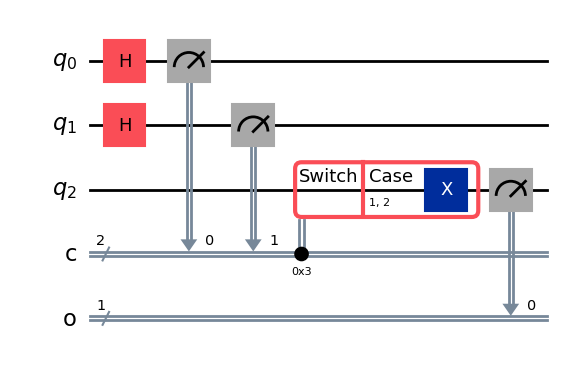

In [42]:
# --- Solution 1 -----------------------------------------------------------
q = QuantumRegister(3, "q"); c = ClassicalRegister(2, "c"); o = ClassicalRegister(1, "o")
sol1 = QuantumCircuit(q, c, o)
sol1.h([0, 1]); sol1.measure([0, 1], c)
with sol1.switch(c) as case:
    with case(0b01, 0b10):       # the two 'bits differ' outcomes share ONE block
        sol1.x(2)
sol1.measure(2, o[0])
check_1(sol1)
display(sol1.draw("mpl"))

In [43]:
# --- Solution 2 -----------------------------------------------------------
sol2 = QuantumCircuit(1, 1)
with sol2.for_loop(range(4)) as i:
    sol2.ry(i * np.pi / 6, 0)    # angles 0, π/6, π/3, π/2 -> sum = π
sol2.measure(0, 0)
check_2(sol2)

✅ Exercise 2 passed — the loop body is stored once and run four times with i = 0..3.


In [44]:
# --- Solution 3 -----------------------------------------------------------
q = QuantumRegister(2); c = ClassicalRegister(2, "c")
sol3 = QuantumCircuit(q, c)
sol3.h(q); sol3.measure(q, c)
with sol3.while_loop(expr.equal(c[0], c[1])):      # loop while the two bits are equal
    sol3.h(q); sol3.measure(q, c)
check_3(sol3)

✅ Exercise 3 passed — {'10': 1498, '01': 1502}


In [45]:
# --- Solution 4 -----------------------------------------------------------
q = QuantumRegister(4, "q"); c = ClassicalRegister(3, "c"); o = ClassicalRegister(1, "o")
sol4 = QuantumCircuit(q, c, o)
sol4.h([0, 1, 2]); sol4.measure([0, 1, 2], c)
c0, c1, c2 = c
maj = expr.logic_or(expr.logic_or(expr.logic_and(c0, c1), expr.logic_and(c0, c2)), expr.logic_and(c1, c2))
with sol4.if_test(maj):
    sol4.x(3)
sol4.measure(3, o[0])
check_4(sol4)

✅ Exercise 4 passed — expression conditions let one if_test replace a whole case table.


In [46]:
# --- Solution 5 -----------------------------------------------------------
# The reference `teleportation(theta, phi)` from section 7 is a valid answer:
print({k: run(teleportation(2.5, -1.2), shots=2000).data.out.get_counts() for k in ["θ=2.5, φ=-1.2"]})
# Protocol recap: Bell pair (q1,q2); CX(q0,q1); H(q0); measure q0->c0, q1->c1; X on q2 if c1; Z on q2 if c0.

{'θ=2.5, φ=-1.2': {'0': 2000}}


In [47]:
# --- Solution 6 -----------------------------------------------------------
ifs = [i.operation for i in mystery.data if i.operation.name == "if_else"]
true_body, false_body = ifs[0].blocks
sol6 = (len(ifs), true_body.count_ops().get("x", 0), sum(false_body.count_ops().values()))
check_6(sol6)
# first if: true body = x,z,x,x -> three x gates; else body = y,h -> two gates; second if_test adds one more if_else.

✅ Exercise 6 passed — blocks are ordinary sub-circuits you can count.


In [48]:
# --- Solution 7 -----------------------------------------------------------
print("dynamic -> no_cf :", False, "| dynamic -> with_cf :", True, "| static -> no_cf :", True)

dynamic -> no_cf : False | dynamic -> with_cf : True | static -> no_cf : True


---
## 13 · One-page summary

- **Dynamic circuit** = mid-circuit `measure`/`reset` + classical **feedforward** (`if_test`, `switch`, `for_loop`, `while_loop`) + small **classical expressions**. `c_if` is **gone**.
- **Builders return context managers** → use `with`. Else: `with qc.if_test(c) as else_:` … `with else_:`.
- **Conditions:** `(Clbit | ClassicalRegister, int)` or a **Bool expression**; register compared as an integer, **bit 0 = LSB**.
- **`switch(target)`:** `with case(v1, v2)`, `case.DEFAULT` last, **no fall-through**.
- **`for_loop(indexset) as i`** — `i` is a `Parameter`, body stored once; **`while_loop(cond)`** — condition must change; `break_loop()` / `continue_loop()` inside loops.
- **Expressions** (`qiskit.circuit.classical.expr`, `types`): `lift`, bitwise `bit_and/or/xor/not`, logical `logic_and/or/not` (no `logic_xor`), comparisons, `index`, shifts, arithmetic; typed `Bool` / `Uint(n)`. **`store(target, value)`** writes the result; `Var`s via `add_var`.
- **Structure:** `IfElseOp`, `SwitchCaseOp`, `ForLoopOp`, `WhileLoopOp` hold **blocks** (sub-circuits) → `.blocks`, `.condition`, `.params`; explicit builders `qc.if_else(...)`, `qc.for_loop(...)`.
- **Run on:** Aer ✔ (some expression kinds unsupported), `StatevectorSampler` / `Statevector` / `Operator` ✘. **Hardware (per IBM docs, verify live):** `if_test` only, Sampler not Estimator, `service.backends(dynamic_circuits=True)`, `MidCircuitMeasure`/`measure_2`, control-electronics limits.
- **Transpile** needs a target that advertises control flow (else `TranspilerError`).
- **Flagship examples:** teleportation with `X`/`Z` corrections; constant-depth **GHZ via parity** (`bit_xor` chain).
- **Next:** Task 3.2 — parameterized circuits (`Parameter`, `ParameterVector`, `assign_parameters`).